# Course: M4010104 / M4020104 — Programming in Python
## Module 2 · Week 7b: Object-Oriented Programming (OOP) in Python
### Classes, Objects, Constructors, Class Variables, Inheritance & Method Overriding
### Interactive Lecture Slides cum Laboratory Practical Workbook
**Digital University Kerala (DUK) · International Centre for Free and Open Source Solutions (ICFOSS)**

---

### Student Identification & Academic Record
*Please complete all entries in this block before beginning your session.*

```
========================================================================================
  STUDENT NAME            : ____________________________________________________________
  ROLL NUMBER / ID        : ____________________________________________________________
  PROGRAMME / BATCH       : [ ] MTech AI    [ ] MSc AI
  DATE OF SESSION         : ____________________________________________________________

========================================================================================
```

---

### Instructional Pacing Guide
- **Interactive Lecture Component**: Follow along with **Dr. Sunil TT**. Execute each demonstration cell, examine line-by-line comments, study the visual class-object memory models, and complete the **In-Class Quick-Checks** after each topic.
  
- **Laboratory Practical Component**: Proceed to **Part 7b: Laboratory Practical Workbook**.
  - **Tier 1 (Core Problems C1–C6)**: Mandatory for all students (15 Marks) — Implementing the complete enterprise `Employee` inheritance hierarchy.



# Encapsulation, Data Protection & Properties

## 1. What is Encapsulation?
**Encapsulation** is one of the fundamental pillars of Object-Oriented Programming (OOP). It refers to the **bundling of data (attributes) and methods (functions)** that operate on that data inside a single unit (a class).

More importantly, encapsulation establishes a **"protective shield"** that prevents external code from directly accessing or modifying an object's internal state. Instead of allowing direct manipulation, access is restricted to authorized interface methods (Getters and Setters).

### Why do we need Encapsulation?
* **Data Integrity & Validation:** Prevents invalid values from being assigned to fields (e.g., setting a vehicle's speed to a negative value or a human's age to 300).
* **Abstraction:** Hides implementation details. The user of a class only needs to know what methods are available, not how they work internally.
* **Flexibility & Maintainability:** If you decide to change how an attribute is stored or calculated internally, you only need to modify the class implementation without breaking the external code that uses it.

---

## 2. Access Modifiers: Naming Conventions in Python
Unlike languages like Java or C++ which have strict keywords (`public`, `protected`, `private`), Python relies entirely on **naming conventions** to indicate the intended visibility of attributes and methods.

| Naming Syntax | Visibility Type | Meaning & Behavioral Characteristics |
| :--- | :--- | :--- |
| `name` | **Public** | **No restrictions.** Accessible directly from outside the class instance. (e.g., `obj.name = "Alice"`) |
| |
| `__name` | **Private** | **Enforced via Name Mangling.** Python automatically renames the attribute to `_ClassName__name` under the hood to prevent accidental modification or inheritance overriding. Direct external access to `__name` will raise an `AttributeError`. |

> ⚠️ ** NOTE :**
> In Python, the single-underscore prefix (like `_heart_rate`) is **strictly a convention for programmers** (a "gentleman's agreement"). It serves as a warning that says: *"This is an internal implementation detail. Please do not modify or read this directly from outside the class."*
>
> However, **Python does not enforce any runtime restrictions on protected attributes.** External code can still read or modify `_heart_rate` directly without throwing any errors. True syntactic enforcement in Python is reserved only for private attributes (with double underscores `__`) via Name Mangling.

---

## 3. The Pythonic Way: `@property` & `@setter` Decorators Explained

To understand how Pythonic getters and setters work, let's look at how decorators act as triggers inside our `BankAccount` class below:

### 1. The `@property` Decorator (The Getter)
* **What it does:** It turns a class method into a read-only "virtual attribute".
* **In our BankAccount:**
  ```python
  @property
  def balance(self):
      return self.__balance
  ```
* **How it behaves:** When you write `print(account.balance)`, Python automatically executes the `balance(self)` method behind the scenes and returns the value of the private `__balance`. Notice that you access it like a property (`account.balance`) instead of calling it like a function (`account.balance()`).

### 2. The `@balance.setter` Decorator (The Setter)
* **What it does:** It associates a validation/modifier function with the property defined above.
* **In our BankAccount:**
  ```python
  @balance.setter
  def balance(self, amount):
      if amount < 0:
          raise ValueError("Negative balance is not allowed!")
      self.__balance = amount
  ```
* **How it behaves:** When you assign a value to the balance attribute (e.g., `account.balance = 1200`), Python intercepts this operation and routes the value `1200` to the `amount` parameter of your setter method. This allows you to inspect, sanitize, and validate the value before it ever touches your private `__balance` variable.

---

## 4. Illustrative Example: The Secure Bank Account

Let's look at a practical example demonstrating how encapsulation prevents a student or developer from accidentally corrupting an object's state.

```python
class BankAccount:
    def __init__(self, owner, initial_balance):
        self.owner = owner               # Public attribute
        self.__balance = initial_balance # Private attribute (Mangled!)

    # Getter Property
    @property
    def balance(self):
        """Allows safe read-only access to balance."""
        return self.__balance

    # Setter Property with Validation
    @balance.setter
    def balance(self, amount):
        """Prevents setting the balance to arbitrary or invalid values directly."""
        if amount < 0:
            raise ValueError("Negative balance is not allowed!")
        self.__balance = amount

    # Controlled Interface Methods
    def deposit(self, amount):
        if amount <= 0:
            raise ValueError("Deposit amount must be positive!")
        self.__balance += amount
        print(f"Deposited Rs. {amount}. New Balance: Rs. {self.__balance}")

    def withdraw(self, amount):
        if amount <= 0:
            raise ValueError("Withdrawal amount must be positive!")
        if amount > self.__balance:
            raise ValueError("Insufficient funds!")
        self.__balance -= amount
        print(f"Withdrew Rs. {amount}. Remaining Balance: Rs. {self.__balance}")
```

### How this protects your data:
* **Direct access blocked:** Attempting to run `account.__balance` from outside the class will immediately crash with an `AttributeError`.
* **Intercepting bad inputs:** If someone tries to execute `account.balance = -500`, the `@balance.setter` catches it immediately and raises a `ValueError` before corrupting the object.

Let's move on to the executable code cells below to see this design pattern in action!

In [ ]:
class BankAccount:
    """
    CONCEPT: CONTROLLED INTERFACE METHODS
    -------------------------------------
    While getters (@property) and setters (@.setter) protect simple attributes,
    complex real-world operations require 'Controlled Interface Methods'.

    Rather than exposing a setter to let anyone rewrite the balance attribute directly
    (e.g., account.balance = 5000), we restrict state changes to dedicated methods
    like 'deposit()' and 'withdraw()'. These methods encapsulate business rules,
    transaction logging, security checks, and robust validation under one interface.
    """
    def __init__(self, owner, initial_balance):
        self.owner = owner               # Public attribute
        self.__balance = initial_balance # Private attribute (Name-mangled!)

    # Getter Property
    @property
    def balance(self):
        """Allows safe read-only access to balance."""
        return self.__balance

    # Setter Property with Validation
    @balance.setter
    def balance(self, amount):
        """Prevents setting the balance to arbitrary or invalid values directly."""
        if amount < 0:
            raise ValueError("Negative balance is not allowed!")
        self.__balance = amount

    # Controlled Interface Methods
    def deposit(self, amount):
        if amount <= 0:
            raise ValueError("Deposit amount must be positive!")
        self.__balance += amount
        print(f"Deposited Rs. {amount}. New Balance: Rs. {self.__balance}")

    def withdraw(self, amount):
        if amount <= 0:
            raise ValueError("Withdrawal amount must be positive!")
        if amount > self.__balance:
            raise ValueError("Insufficient funds!")
        self.__balance -= amount
        print(f"Withdrew Rs. {amount}. Remaining Balance: Rs. {self.__balance}")

# --- DEMONSTRATION & ERROR HANDLING ---

account = BankAccount("Alice", 1000.0)
print(f"Account Owner: {account.owner}")
print(f"Initial Balance (via @property): Rs. {account.balance}\n")

# 1. Attempting to directly access the raw __balance private variable
try:
    print("Attempting to access account.__balance directly...")
    print(account.__balance)
except AttributeError as e:
    print(f"[ERROR CAUGHT] Direct access failed: {e}")
    print("Explanation: Python name-mangles self.__balance to self._BankAccount__balance, making it inaccessible directly via '__balance'.\n")

# 2. Attempting to directly assign a negative value using the property setter
try:
    print("Attempting to set balance to -500.0 via the property setter...")
    account.balance = -500.0
except ValueError as e:
    print(f"[ERROR CAUGHT] Setter validation failed: {e}\n")

# 3. Correct usage via proper interface methods
print("--- Performing valid transactions via approved methods ---")
account.deposit(500.0)
account.withdraw(300.0)
print(f"Final Balance: Rs. {account.balance}")

Account Owner: Alice
Initial Balance (via @property): Rs. 1000.0

Attempting to access account.__balance directly...
[ERROR CAUGHT] Direct access failed: 'BankAccount' object has no attribute '__balance'
Explanation: Python name-mangles self.__balance to self._BankAccount__balance, making it inaccessible directly via '__balance'.

Attempting to set balance to -500.0 via the property setter...
[ERROR CAUGHT] Setter validation failed: Negative balance is not allowed!

--- Performing valid transactions via approved methods ---
Deposited Rs. 500.0. New Balance: Rs. 1500.0
Withdrew Rs. 300.0. Remaining Balance: Rs. 1200.0
Final Balance: Rs. 1200.0


### In-Class Quick Check 4: Encapsulation
**Task**:
1. Create a class `PatientVitals` with constructor accepting `patient_id` and `heart_rate`.
2. Store `_heart_rate` as a protected attribute.
3. Create a property `heart_rate` with a setter that raises a `ValueError` if heart rate is not between $30$ and $220$ bpm.


In [ ]:
# STUDENT ACTIVITY: (Encapsulation Exercise) Make resonable assumptions
# -------------------------------------------------------------------

class PatientVitals:
    def __init__(self, patient_id, heart_rate):
        self.patient_id = patient_id
        # TODO: Assign the parameter to the property (which triggers the setter validation)
        self.heart_rate = heart_rate

    # 1. Define the getter property using the @property decorator
    @property
    def heart_rate(self):
        # TODO: Return the underlying protected attribute (_heart_rate)
        pass

    # 2. Define the setter property using the @heart_rate.setter decorator
    @heart_rate.setter
    def heart_rate(self, bpm):
        # TODO: Validate that bpm is in the range [30, 220]
        # Raise a ValueError("Invalid heart rate") if it is outside this range
        # Otherwise, save it in the protected attribute (_heart_rate)
        pass

# --- Test Cases to Verify Your Code ---
try:
    # This should initialize successfully
    pv = PatientVitals("P-101", 72)
    print(f"Patient {pv.patient_id} Heart Rate: {pv.heart_rate} bpm")
    assert pv.heart_rate == 72, "Heart rate getter not returning the correct value"

    # This should raise a ValueError
    print("Testing invalid heart rate validation (250 bpm)... ")
    pv.heart_rate = 250
    print("❌ Error: The setter failed to raise ValueError for 250 bpm!")
except ValueError as e:
    print(f"✅ Successfully caught validation error: {e}")
except Exception as e:
    print(f"❌ Unexpected error occurred: {type(e).__name__} - {e}")

---
#   Inheritance, Method Overriding & Polymorphism (`super()`)

**Inheritance** allows a new class (the **Derived / Child class**) to inherit attributes and methods from an existing class (the **Base / Parent class**), establishing an "IS-A" relationship.


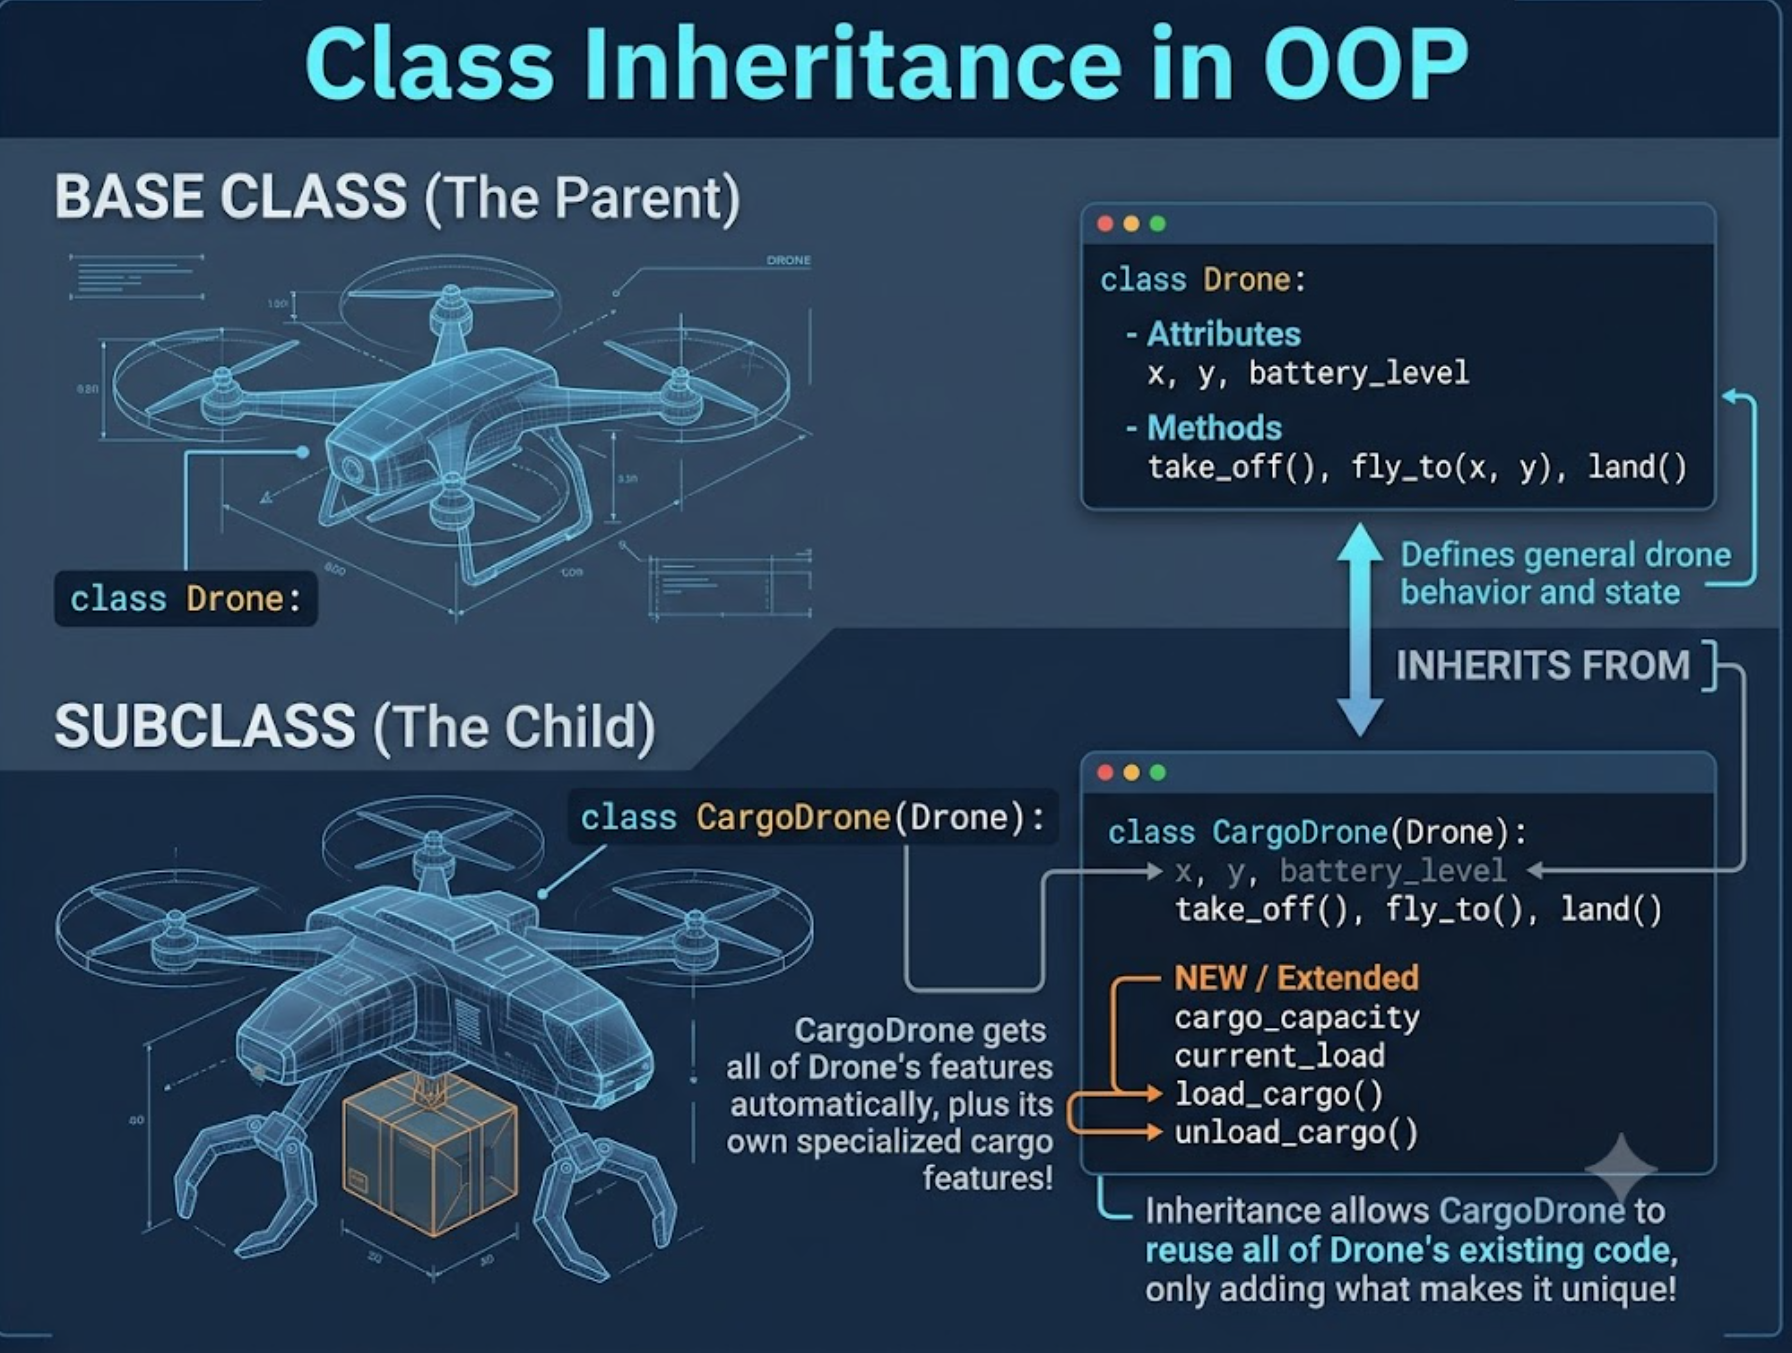

In [ ]:
class Drone:
    """Base Parent Class representing a generic Unmanned Aerial Vehicle (UAV)."""
    def __init__(self, drone_id, model, x=0.0, y=0.0, battery_level=100.0):
        self.drone_id = drone_id
        self.model = model
        self.x = float(x)
        self.y = float(y)
        self.battery_level = float(battery_level)
        self.is_flying = False

    def takeoff(self):
        self.is_flying = True
        print(f"[{self.drone_id}] Drone has taken off and is now airborne.")

    def land(self):
        self.is_flying = False
        print(f"[{self.drone_id}] Drone has safely landed.")

    def get_specs(self):
        return f"ID: {self.drone_id} | Model: {self.model} | Position: ({self.x}, {self.y}) | Battery: {self.battery_level}%"


# Derived Child Class demonstrating inheritance
class DeliveryDrone(Drone):
    """Specialized Child Class for carrying and delivering packages."""
    def __init__(self, drone_id, model, x, y, battery_level, payload_capacity_kg):
        # 1. Delegate core initialization to the parent class using super()
        super().__init__(drone_id, model, x, y, battery_level)

        # 2. Add specialized attribute
        self.payload_capacity_kg = float(payload_capacity_kg)

    # 3. Add specialized method
    def deliver_package(self, package_weight, destination):
        if not self.is_flying:
            print(f"[Error] Cannot deliver: {self.drone_id} is still on the ground!")
            return
        if package_weight > self.payload_capacity_kg:
            print(f"[Error] Package weight ({package_weight} kg) exceeds maximum payload capacity ({self.payload_capacity_kg} kg)!")
            return
        print(f"[{self.drone_id}] Successfully delivered a {package_weight} kg package to {destination}!")

    # Method Overriding: Specialize get_specs() to include payload info
    def get_specs(self):
        base_specs = super().get_specs()
        return f"{base_specs} | Payload Capacity: {self.payload_capacity_kg} kg"


# --- Demonstration of the Inheritance and Specialized Functionality ---

    # Instantiate a DeliveryDrone object with the new coordinate and battery attributes
    my_delivery_drone = DeliveryDrone("DRONE-99", "Quadcopter-V2", x=10.0, y=20.0, battery_level=95.0, payload_capacity_kg=5.5)

    # Display specs (demonstrating method overriding and super() call)
    print(my_delivery_drone.get_specs())

    # Attempting to deliver package before takeoff
    my_delivery_drone.deliver_package(3.0, "Warehouse A")

    # Flying and successfully executing a delivery
    my_delivery_drone.takeoff()
    my_delivery_drone.deliver_package(3.0, "Warehouse A")
    my_delivery_drone.land()

ID: DRONE-99 | Model: Quadcopter-V2 | Position: (10.0, 20.0) | Battery: 95.0% | Payload Capacity: 5.5 kg
[Error] Cannot deliver: DRONE-99 is still on the ground!
[DRONE-99] Drone has taken off and is now airborne.
[DRONE-99] Successfully delivered a 3.0 kg package to Warehouse A!
[DRONE-99] Drone has safely landed.


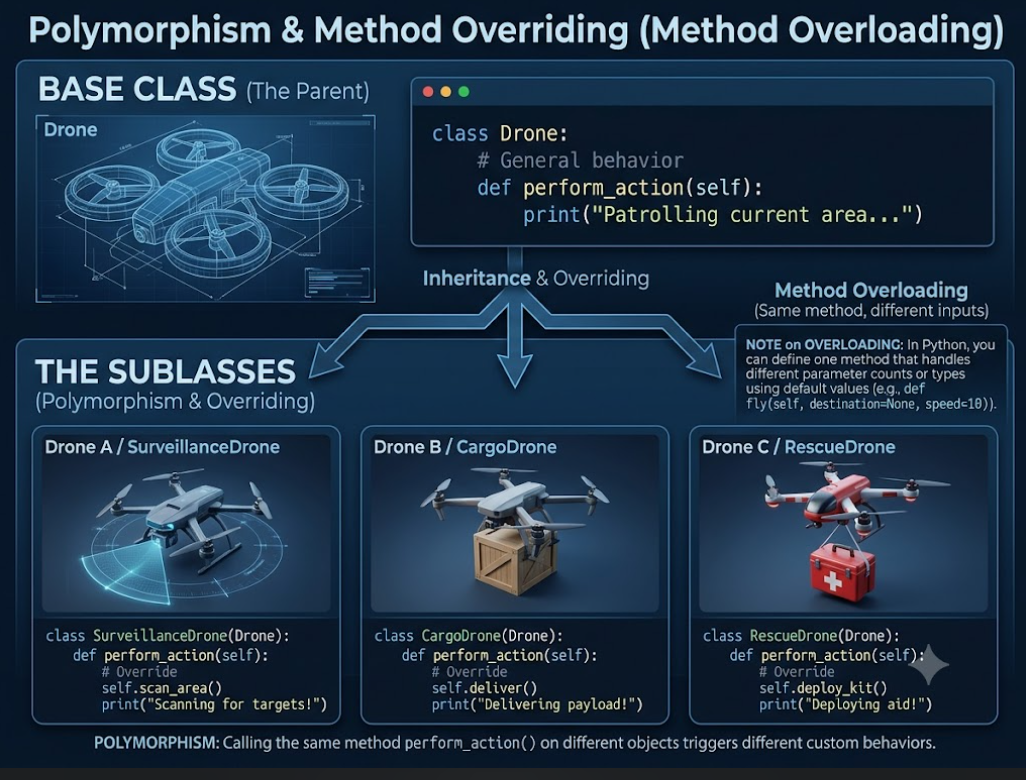

In [ ]:
# 5.1 Base Class and Derived Subclass with super()
class HardwareDevice:
    '''Base Parent Class for all laboratory devices.'''
    def __init__(self, device_id, manufacturer, power_watts):
        self.device_id = device_id
        self.manufacturer = manufacturer
        self.power_watts = float(power_watts)
        self.is_powered = False

    def power_on(self):
        self.is_powered = True
        print(f"[{self.device_id}] Power ON ({self.power_watts} W draw)")

    def power_off(self):
        self.is_powered = False
        print(f"[{self.device_id}] Power OFF")

    def get_specs(self):
        return f"ID: {self.device_id} | Maker: {self.manufacturer} | Power: {self.power_watts}W"

# Subclass: CameraSensor IS-A HardwareDevice
class CameraSensor(HardwareDevice):
    '''Derived Child Class specializing in optical imaging.'''
    def __init__(self, device_id, manufacturer, power_watts, resolution_mp, framerate_fps):
        # 1. Delegate common initialization to parent class using super()!
        super().__init__(device_id, manufacturer, power_watts)

        # 2. Initialize specialized camera attributes:
        self.resolution_mp = resolution_mp
        self.framerate_fps = framerate_fps

    # Method Overriding: Specialize get_specs() for camera sensors:
    def get_specs(self):
        base_specs = super().get_specs()  # Call parent implementation
        return f"{base_specs} | Sensor: {self.resolution_mp}MP @ {self.framerate_fps}fps"

    def capture_frame(self):
        if not self.is_powered:
            print(f"[Error] Cannot capture: {self.device_id} is powered off!")
            return None
        print(f"[{self.device_id}] Frame captured at {self.resolution_mp} MP.")
        return f"<RawFrameData_{self.device_id}>"

cam = CameraSensor("CAM-01", "Sony", 12.0, resolution_mp=48, framerate_fps=60)
print(cam.get_specs())
cam.power_on()
cam.capture_frame()


In [ ]:
# 5.2 Polymorphism in Action (Iterating across Heterogeneous Objects)
# Polymorphism allows treating different subclasses through a uniform interface!

class EdgeComputeNode(HardwareDevice):
    '''Edge AI Accelerator device.'''
    def __init__(self, device_id, manufacturer, power_watts, tops_compute):
        super().__init__(device_id, manufacturer, power_watts)
        self.tops_compute = tops_compute

    def get_specs(self):
        return f"{super().get_specs()} | AI Compute: {self.tops_compute} TOPS"

# Heterogeneous device rack:
lab_rack = [
    HardwareDevice("PSU-01", "Delta", 750.0),
    CameraSensor("CAM-02", "OmniVision", 8.0, 16, 30),
    EdgeComputeNode("JETSON-01", "Nvidia", 25.0, 40)
]

print("=== Heterogeneous Device Rack Audit (Polymorphism) ===")
total_power = 0.0
for dev in lab_rack:
    # Each device executes its OWN version of get_specs() polymorphically!
    print(" *", dev.get_specs())
    total_power += dev.power_watts

print(f"Total Rack Power Draw: {total_power} Watts")


### 📚 Why Do We Need Abstract Base Classes (ABCs)?

In large software projects, you often need to define a **common interface** (a strict set of rules or templates) that multiple different classes must follow.

Without **Abstract Base Classes**, there is no way to force programmers to implement certain crucial methods in their subclasses. This can lead to runtime crashes when a client expects a method to exist but a developer forgot to write it.

#### The Solution: The `abc` Module
Using Python's built-in `abc` module, we can define an **Abstract Base Class (ABC)**.
1. **Enforces a Contract**: Any subclass inheriting from our ABC **must** implement all methods marked with `@abstractmethod`. If they don't, Python will raise a `TypeError` and refuse to let the program instantiate that subclass.
2. **Prevents Direct Instantiation**: You cannot instantiate an abstract class itself directly. It serves only as a blueprint.

---
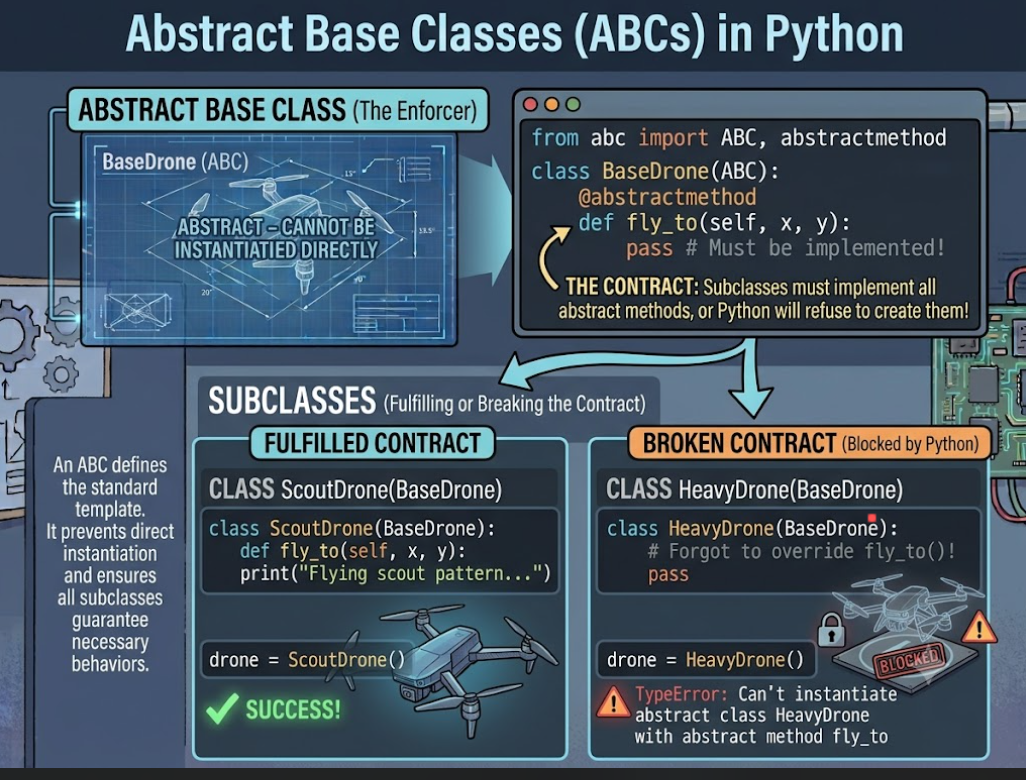

### 💻 Practical Implementation: Defining and Using ABCs

In [1]:
from abc import ABC, abstractmethod

class BaseDrone(ABC):
    """
    The Abstract Base Class (Blueprint).
    It defines the exact interface every specific drone type must support.
    """
    def __init__(self, drone_id, battery_level):
        self.drone_id = drone_id
        self.battery_level = battery_level

    @abstractmethod
    def fly_to(self, x, y):
        """Abstract method: Every subclass must implement how it navigates."""
        pass

    @abstractmethod
    def perform_action(self):
        """Abstract method: Every subclass must implement its core objective."""
        pass

# --- Creating a conforming subclass ---
class SurveillanceDrone(BaseDrone):
    """Concrete class implementing all abstract methods."""
    def fly_to(self, x, y):
        print(f"[Surveillance] Flying silently to target location: ({x}, {y})")

    def perform_action(self):
        print("[Surveillance] Activating optical zoom and streaming real-time video.")

# --- Testing our Design Contract ---
if __name__ == "__main__":
    # 1. Verification of Safe Protection: This block will raise an error if run!
    print("--- Attempting to instantiate the Abstract Base class --- ")
    try:
        abstract_obj = BaseDrone("GENERIC-01", 100.0)
    except TypeError as e:
        print(f"✅ Successfully Blocked: {e}")

    print("\n--- Instantiating and using the Concrete Subclass ---")
    spy_drone = SurveillanceDrone("SPY-701", 92.5)
    spy_drone.fly_to(50.4, -12.8)
    spy_drone.perform_action()

--- Attempting to instantiate the Abstract Base class --- 
✅ Successfully Blocked: Can't instantiate abstract class BaseDrone without an implementation for abstract methods 'fly_to', 'perform_action'

--- Instantiating and using the Concrete Subclass ---
[Surveillance] Flying silently to target location: (50.4, -12.8)
[Surveillance] Activating optical zoom and streaming real-time video.


### Quick Check : Inheritance
**Task**:
1. Create a base class `Vehicle` with `brand` and `speed`.
2. Create a subclass `ElectricVehicle(Vehicle)` that uses `super().__init__(brand, speed)` and adds `battery_kwh`.
3. Override a `display_info()` method to print brand, speed, and battery capacity.


In [ ]:
# STUDENT ACTIVITY: Quick Check 5
# -------------------------------------------------------------
class Vehicle:
    def __init__(self, brand, speed):
        self.brand = brand
        self.speed = speed

    def display_info(self):
        return f"Brand: {self.brand} | Speed: {self.speed} km/h"

class ElectricVehicle(Vehicle):
    def __init__(self, brand, speed, battery_kwh):
        # TODO: Call super and initialize battery
        super().__init__(brand, speed)
        self.battery_kwh = battery_kwh

    def display_info(self):
        # TODO: Override display_info
        return f"{super().display_info()} | Battery: {self.battery_kwh} kWh"

ev = ElectricVehicle("Tata Nexon EV", 140, 40.5)
print(ev.display_info())
assert "40.5 kWh" in ev.display_info()


# Operator Overloading in Python

### 1. What is Operator Overloading?
**Operator Overloading** is a specific form of polymorphism where different operators (like `+`, `-`, `*`, `/`, `<`, `>`, `==`) have different behaviors depending on the data types of their operands.

For example, the `+` operator behaves differently depending on what it is operating on:
* **Addition** for numbers: `5 + 3` results in `8`.
* **Concatenation** for strings: `"Hello " + "World"` results in `"Hello World"`.

In Python, you can define how operators behave with your custom objects by implementing special "dunder" (double underscore) methods in your class.

---

### 2. Common Operator Overloading Methods

| Operator | Magic (Dunder) Method | Purpose |
| :---: | :--- | :--- |
| `+` | `__add__(self, other)` | Addition |
| `-` | `__sub__(self, other)` | Subtraction |
| `*` | `__mul__(self, other)` | Multiplication |
| `<` | `__lt__(self, other)` | Less than |
| `==` | `__eq__(self, other)` | Equality |

---
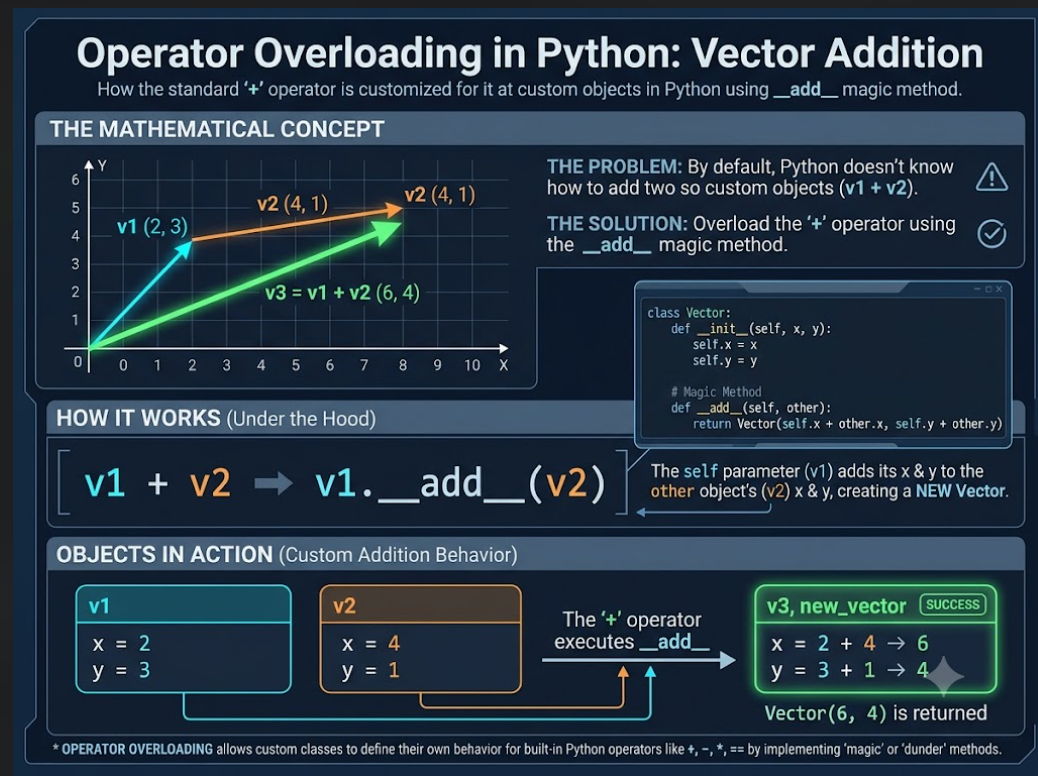

### 3. Example: Vector Addition

Let's look at how we can overload the `+` operator so we can add two coordinate points or mathematical vectors directly using `v1 + v2`.

```python
class Vector2D:
    def __init__(self, x, y):
        self.x = x
        self.y = y

    # Overloading the + operator
    def __add__(self, other):
        if isinstance(other, Vector2D):
            return Vector2D(self.x + other.x, self.y + other.y)
        return NotImplemented

    # Controlling how the vector is printed
    def __str__(self):
        return f"Vector({self.x}, {self.y})"

# Usage:
v1 = Vector2D(2, 4)
v2 = Vector2D(5, -1)

# This internally calls: v1.__add__(v2)
result_vector = v1 + v2
print(result_vector)  # Output: Vector(7, 3)
```

### Quick Check: Operator Overloading
**Task**:
1. Create a class `Vector2D` that represents a 2-dimensional vector with coordinate values `x` and `y`.
2. Overload the subtraction (`-`) operator using `__sub__` to allow subtracting one `Vector2D` object from another.
3. Overload the multiplication (`*`) operator using `__mul__` to allow scaling the vector coordinates by a scalar number (integer or float).
4. Overload the `__str__` method to return a string representation of the vector in the format `(x, y)`.

In [ ]:
# STUDENT ACTIVITY: Quick Check on Operator Overloading
# -------------------------------------------------------------
class Vector2D:
    def __init__(self, x, y):
        self.x = x
        self.y = y

    # TODO: Overload the '-' operator to subtract coordinate values
    def __sub__(self, other):
        # Your code here
        pass

    # TODO: Overload the '*' operator to scale the vector by a scalar number
    def __mul__(self, scalar):
        # Your code here
        pass

    # TODO: Overload __str__ to represent the object as "(x, y)"
    def __str__(self):
        # Your code here
        pass

# --- Test Cases to Verify Your Code ---
try:
    v1 = Vector2D(5, 8)
    v2 = Vector2D(2, 3)

    # Test Subtraction
    diff_vector = v1 - v2
    print(f"Vector 1: {v1}")
    print(f"Vector 2: {v2}")
    print(f"Subtraction (v1 - v2): {diff_vector}")

    # Test Scaling (Multiplication)
    scaled_vector = v1 * 3
    print(f"Scaled (v1 * 3): {scaled_vector}")



# C Student Task T1 ( Mandatory) : E-Commerce Shopping Cart Engine


### Imagine you are building the backend logic for a modern e-commerce platform. When customers add items to their carts, the system must process base pricing, apply dynamic promotional discounts, validate that prices are never negative (to prevent checkout exploits), and quickly aggregate totals.

To build this securely and cleanly, you will implement an OOP model:

1. **Encapsulation**: Create a base class `Item` with `name` and a private attribute `__price`. Expose a Python `@property` getter and setter for `price` to protect your data. The setter must guard the system against negative pricing errors by raising a `ValueError` if a price below zero is entered.
2. **Inheritance & Polymorphism**: Create a subclass `DiscountedItem` that inherits from `Item`. It should accept a third parameter `discount_rate` (a float from `0.0` to `1.0`). Override the `price` property to return the price after applying the markdown (e.g., $100$ base price with a $0.20$ discount rate should dynamically evaluate to $80.0$).
3. **Operator Overloading**: Overload the addition (`+`) operator on the `Item` base class using the `__add__` magic method. When two items (either base items or discounted items) are added together (e.g., `item1 + item2`), it should calculate and return their combined checkout cost.

In [ ]:
# STUDENT ACTIVITY: Inheritance, Encapsulation & Operator Overloading
# -------------------------------------------------------------

class Item:
    def __init__(self, name, price):
        self.name = name
        # TODO: Initialize the private price attribute using the setter
        self.price = price

    # TODO: Define a property getter for price
    @property
    def price(self):
        pass

    # TODO: Define a property setter for price that raises ValueError if price < 0
    @price.setter
    def price(self, value):
        pass

    # TODO: Overload the '+' operator to return the sum of prices of two items
    def __add__(self, other):
        pass


class DiscountedItem(Item):
    def __init__(self, name, price, discount_rate):
        # TODO: Initialize base class and the discount_rate attribute
        pass

    # TODO: Override the price getter to return price with discount_rate applied
    # Formula: discounted_price = base_price * (1 - discount_rate)


# --- Test Cases to Verify Your Code ---
try:
    # Test Encapsulation & Setters
    book = Item("Python Book", 500)
    try:
        book.price = -100
        print("❃ Error: Negative price was accepted!")
    except ValueError:
        print("✅ Correctly blocked negative price.")

    # Test Inheritance and Overriding
    promo_book = DiscountedItem("Python Book Promo", 500, 0.2) # 20% off
    print(f"Original Book Price: Rs. {book.price}")
    print(f"Discounted Book Price: Rs. {promo_book.price}")
    assert promo_book.price == 400.0, "Discounted price calculation is incorrect!"

    # Test Operator Overloading
    total_cost = book + promo_book
    print(f"Total Cost of both books: Rs. {total_cost}")
    assert total_cost == 900.0, "Operator overloading addition is incorrect!"

    print("\n✅ All tests passed successfully!")
except Exception as e:
    print(f"\n❃ Test failed. Error: {e}")

 ### Task A1: Machine Learning Model Abstract Base Class (`abc.ABC`)
**Context**: Machine learning frameworks (Scikit-Learn) enforce standard interfaces (`fit`, `predict`) using Abstract Base Classes.

**Problem Statement**:
1. Use `from abc import ABC, abstractmethod` to define `BaseEstimator(ABC)`.
2. Define abstract methods `fit(self, X, y)` and `predict(self, X)`.
3. Implement a concrete subclass `ZeroRuleClassifier(BaseEstimator)` that predicts the most common class label.
4. Verify that attempting to instantiate `BaseEstimator` directly raises `TypeError`.


In [ ]:
# TASK A3: WORKSPACE (ADVANCED)
# -------------------------------------------------------------
from abc import ABC, abstractmethod

class BaseEstimator(ABC):
    '''Abstract Base Class enforcing the Scikit-Learn API contract.'''
    @abstractmethod
    def fit(self, X, y):
        pass

    @abstractmethod
    def predict(self, X):
        pass

class ZeroRuleClassifier(BaseEstimator):
    '''Predicts the majority class from training data.'''
    def __init__(self):
        self.majority_class = None

    def fit(self, X, y):
        # Find most frequent class label in y
        self.majority_class = max(set(y), key=y.count)
        return self

    def predict(self, X):
        return [self.majority_class] * len(X)

# Test instantiation:
clf = ZeroRuleClassifier()
clf.fit([[1, 2], [3, 4], [5, 6]], y=["cat", "dog", "dog"])
predictions = clf.predict([[7, 8], [9, 10]])
print("Predictions from ZeroRuleClassifier:", predictions)

# Verify ABC protection:
try:
    bad_instance = BaseEstimator()
    assert False, "Should not allow instantiation of Abstract Base Class"
except TypeError as e:
    print("Caught Expected ABC Instantiation Error:", e)

assert predictions == ["dog", "dog"]
print(" Task A3 Verified Successfully!")


Predictions from ZeroRuleClassifier: ['dog', 'dog']
Caught Expected ABC Instantiation Error: Can't instantiate abstract class BaseEstimator without an implementation for abstract methods 'fit', 'predict'
 Task A3 Verified Successfully!


---
## 6: Laboratory Evaluation Rubric & Sign-Off Sheet

```
========================================================================================
CRITERION                                  MAX MARKS    AWARDED MARKS    REMARKS
========================================================================================
1. In-Class Quick Checks (Lecture Part 1–5)    5          _______        _______________
2. Tier 1 Core Problems (§6: C1 complete)  10          _______        _______________
3. Code Cleanliness, Comments & OOP Design     5          _______        _______________
4. Tier 2 Advanced Problems (§4) / Viva        5          _______        _______________
----------------------------------------------------------------------------------------
TOTAL SCORE                                   25          _______ / 25
========================================================================================

Teaching Assistant Signature : _________________________________
Faculty Instructor Signature : Dr. Sunil TT (Director, ICFOSS)
Date of Evaluation           : _________________________________
```
